In [ ]:
# [셀 D1] ⑥ 정책 매트릭스 틀: 취약지역을 공간 패턴(행) × 원인 유형(열)으로 교차
import os, numpy as np, pandas as pd
from google.colab import files
if not all(os.path.exists(f) for f in ["dong_master.csv", "kmeans_input.csv"]):
    for f in files.upload():
        for base in ["dong_master", "kmeans_input"]:
            if f.startswith(base) and f != base + ".csv": os.rename(f, base + ".csv")
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str, "cluster": str})
ROWS = ["밀집형", "고립형", "산발형"]
COLS = ["의료·교통 동시 취약형", "고령 1인가구 밀집형", "평균형", "의료 양호형", "도서형"]
V = dm[dm["vuln"] != "비취약"].copy()
V["pattern"] = pd.Categorical(V["pattern"], ROWS); V["cluster_nm"] = pd.Categorical(V["cluster_nm"], COLS)
print(pd.crosstab(V["pattern"], V["cluster_nm"], margins=True, margins_name="합계", dropna=False).to_string())
for (p, c), d in V.groupby(["pattern", "cluster_nm"], observed=True):
    print(f"\n[{p} × {c}] {len(d)}개:", [n + ("(경계)" if v == "경계" else "") for n, v in zip(d["adm_nm"], d["vuln"])])

Saving dong_master_new.csv to dong_master_new.csv
Saving kmeans_input_new.csv to kmeans_input_new.csv
cluster_nm  의료·교통 동시 취약형  고령 1인가구 밀집형  평균형  의료 양호형  도서형  합계
pattern                                                    
밀집형                    9            0    0       0    4  13
고립형                    0            1    0       0    0   1
산발형                    4            6    5       0    2  17
합계                    13            7    5       0    6  31

[밀집형 × 의료·교통 동시 취약형] 9개: ['불은면', '길상면', '화도면', '양도면', '내가면', '하점면', '양사면', '교동면', '삼산면']

[밀집형 × 도서형] 4개: ['서도면', '북도면', '덕적면', '자월면']

[고립형 × 고령 1인가구 밀집형] 1개: ['삼산1동']

[산발형 × 의료·교통 동시 취약형] 4개: ['용유동', '선원면', '송해면', '영흥면']

[산발형 × 고령 1인가구 밀집형] 6개: ['개항동', '만석동', '화수1·화평동(경계)', '화수2동', '부평3동', '문학동']

[산발형 × 평균형] 5개: ['영종동', '송현1·2동(경계)', '장수서창동', '산곡3동', '계양1동(경계)']

[산발형 × 도서형] 2개: ['백령면', '대청면']


In [ ]:
# [셀 D2] 칸별 프로필: 칸 평균 z + 동별 원래 값·z·고령인구 수
X = pd.read_csv("kmeans_input.csv", dtype={"adm_cd": str})
ZC = ["acc_600_z", "d_bus_w_z", "eld_single_ratio_z"]
P = V.merge(X[["adm_cd"] + ZC], on="adm_cd", how="left")      # d_bus_w는 dong_master 것을 그대로 씀
pd.set_option("display.width", 200)
print(P.groupby(["pattern", "cluster_nm"], observed=True).agg(동수=("adm_cd", "size"), **{z: (z, "mean") for z in ZC}).round(2).to_string())
for (p, c), d in P.groupby(["pattern", "cluster_nm"], observed=True):
    print(f"\n[{p} × {c}]")
    print(d[["adm_nm", "vuln", "acc_600", "d_bus_w", "eld_single_ratio"] + ZC + ["eld_65", "eld_single"]].round(2).to_string(index=False))

                      동수  acc_600_z  d_bus_w_z  eld_single_ratio_z
pattern cluster_nm                                                
밀집형     의료·교통 동시 취약형   9      -1.80       2.62                0.19
        도서형            4        NaN        NaN                 NaN
고립형     고령 1인가구 밀집형    1      -0.96      -0.63                0.73
산발형     의료·교통 동시 취약형   4      -1.66       2.07                0.59
        고령 1인가구 밀집형    6      -1.31      -0.20                1.00
        평균형            5      -1.16      -0.33               -0.49
        도서형            2        NaN        NaN                 NaN

[밀집형 × 의료·교통 동시 취약형]
adm_nm vuln  acc_600  d_bus_w  eld_single_ratio  acc_600_z  d_bus_w_z  eld_single_ratio_z  eld_65  eld_single
   불은면   확정     0.00    272.0             33.13      -1.86       2.72                0.50    2487         824
   길상면   확정     0.32    259.8             27.88      -1.30       2.56               -0.16    3092         862
   화도면   확정     0.00    270.3             30.

In [ ]:
# [셀 D3] ⑥ 칸별 대응 붙이기 → 정책 매트릭스 + 대응별 우선순위
UNIT = {"밀집형": "권역 단위", "고립형": "동 단위 + 인접 동 연계", "산발형": "동 단위"}
RESP = {("밀집형", "의료·교통 동시 취약형"): "의료시설 확충 검토 + 이동형 의료",
        ("밀집형", "도서형"):               "이동형 의료",
        ("고립형", "고령 1인가구 밀집형"):   "병원 동행",
        ("산발형", "의료·교통 동시 취약형"): "이동형 의료",
        ("산발형", "고령 1인가구 밀집형"):   "병원 동행",
        ("산발형", "평균형"):               "의료 정보 제공",
        ("산발형", "도서형"):               "이동형 의료"}      # ← D2 보고 칸마다 붙인 대응
key = list(zip(P["pattern"].astype(str), P["cluster_nm"].astype(str)))
P["unit"], P["policy"] = P["pattern"].astype(str).map(UNIT), [RESP.get(k, "미지정") for k in key]
print("대응이 안 붙은 동:", P.loc[P["policy"] == "미지정", "adm_nm"].tolist())
mat = P.groupby(["pattern", "cluster_nm"], observed=False)["policy"].agg(lambda s: f"{s.iloc[0]} ({len(s)})" if len(s) else "-").unstack()
mat.index = [f"{p} [{UNIT[p]}]" for p in mat.index]
print("\n[정책 매트릭스] 칸 = 대응 (동 수)\n" + mat.to_string())
P["기준"] = np.where(P["policy"] == "병원 동행", P["eld_single"], P["eld_65"])
P = P.assign(확정=P["vuln"] == "확정").sort_values(["policy", "확정", "기준"], ascending=[True, False, False])
P["rank"] = P.groupby("policy").cumcount() + 1
for pol, d in P.groupby("policy", sort=False):
    print(f"\n[{pol}] 정렬: 확정 먼저 → {'고령 1인가구 수' if pol == '병원 동행' else '고령인구 수'}")
    print(d[["rank", "adm_nm", "vuln", "pattern", "eld_65", "eld_single"]].to_string(index=False))

대응이 안 붙은 동: []

[정책 매트릭스] 칸 = 대응 (동 수)
cluster_nm                       의료·교통 동시 취약형 고령 1인가구 밀집형           평균형 의료 양호형         도서형
밀집형 [권역 단위]           의료시설 확충 검토 + 이동형 의료 (9)         NaN           NaN    NaN  이동형 의료 (4)
고립형 [동 단위 + 인접 동 연계]                      NaN   병원 동행 (1)           NaN    NaN         NaN
산발형 [동 단위]                         이동형 의료 (4)   병원 동행 (6)  의료 정보 제공 (5)    NaN  이동형 의료 (2)

[병원 동행] 정렬: 확정 먼저 → 고령 1인가구 수
 rank  adm_nm vuln pattern  eld_65  eld_single
    1    삼산1동   확정     고립형    6617        2315
    2    부평3동   확정     산발형    3390        1228
    3     문학동   확정     산발형    2516         943
    4    화수2동   확정     산발형    2493         935
    5     개항동   확정     산발형    2285         895
    6     만석동   확정     산발형    1852         662
    7 화수1·화평동   경계     산발형    1894         697

[의료 정보 제공] 정렬: 확정 먼저 → 고령인구 수
 rank adm_nm vuln pattern  eld_65  eld_single
    1   산곡3동   확정     산발형    5742        1388
    2    영종동   확정     산발형    4958        1471
    3  장수서창동   확정    

In [ ]:
# [셀 D4-0] 경계 파일 올리기 (없을 때만)
if not os.path.exists("dong_boundary.gpkg"):
    for f in files.upload():
        if f.startswith("dong_boundary") and f != "dong_boundary.gpkg": os.rename(f, "dong_boundary.gpkg")
print("경계 파일 있음:", os.path.exists("dong_boundary.gpkg"))

Saving dong_boundary.gpkg to dong_boundary.gpkg
경계 파일 있음: True


In [ ]:
# [셀 D4] 밀집형 권역 묶기 + 권역 거점 후보 + 고립형 연계 동 (④와 같은 이웃 관계)
import warnings, geopandas as gpd
from libpysal.weights import Queen, KNN
from scipy.sparse.csgraph import connected_components
warnings.filterwarnings("ignore")
g = gpd.read_file("dong_boundary.gpkg").to_crs(5179).astype({"adm_cd": str})[["adm_cd", "geometry"]].merge(dm, on="adm_cd").reset_index(drop=True)
wq = Queen.from_dataframe(g, use_index=False, silence_warnings=True)
wk = KNN.from_dataframe(g, k=4, use_index=False)
nb = {i: list(wq.neighbors[i]) or list(wk.neighbors[i]) for i in range(len(g))}       # B3과 같은 규칙
pos, vul = {cd: i for i, cd in enumerate(g["adm_cd"])}, set(P["adm_cd"])
def helpers(members):                                   # 묶음 밖 비취약 이웃 동, 접근성 높은 순 3개
    out = {j for m in members for j in nb[pos[m]]} - {pos[m] for m in members}
    h = g.loc[sorted(out)]; h = h[~h["adm_cd"].isin(vul)]
    h = h.sort_values("acc_600", ascending=False)[["adm_nm", "acc_600", "lisa", "cluster_nm"]].head(3).round(2)
    return h.to_string(index=False) if len(h) else "  붙어 있는 비취약 동 없음"
C = P.loc[P["pattern"] == "밀집형", "adm_cd"].tolist(); idx = [pos[c] for c in C]
A = np.array([[(j in nb[i]) or (i in nb[j]) for j in idx] for i in idx], int)
ncomp, lab = connected_components(A, directed=False)
P["region"] = P["adm_cd"].map(dict(zip(C, [f"권역{l + 1}" for l in lab])))
for r, d in P[P["region"].notna()].groupby("region"):
    print(f"\n[{r}] {len(d)}개 동:", d["adm_nm"].tolist())
    print("  거점 후보 (붙어 있는 비취약 동, 접근성 높은 순)\n" + helpers(d["adm_cd"]))
for _, r in P[P["pattern"] == "고립형"].iterrows():
    print(f"\n[고립형 {r['adm_nm']}] 연계할 이웃 동\n" + helpers([r["adm_cd"]]))


[권역1] 11개 동: ['길상면', '불은면', '화도면', '하점면', '양도면', '내가면', '교동면', '삼산면', '양사면', '북도면', '서도면']
  거점 후보 (붙어 있는 비취약 동, 접근성 높은 순)
adm_nm  acc_600 lisa  cluster_nm
   강화읍     1.99   HL 고령 1인가구 밀집형
   운서동     1.20   LL         평균형

[권역2] 2개 동: ['덕적면', '자월면']
  거점 후보 (붙어 있는 비취약 동, 접근성 높은 순)
adm_nm  acc_600 lisa cluster_nm
   운서동      1.2   LL        평균형

[고립형 삼산1동] 연계할 이웃 동
adm_nm  acc_600 lisa cluster_nm
 작전서운동     6.79   ns     의료 양호형
  작전1동     5.37   ns     의료 양호형
  삼산2동     1.89   ns        평균형


In [ ]:
# [셀 D4-1] 권역 이름 붙이기 (D4 출력 보고 붙인 이름)
P["region"] = P["region"].map({"권역1": "강화 권역", "권역2": "덕적·자월 권역"})
P["hub"] = P["region"].map({"강화 권역": "강화읍", "덕적·자월 권역": "뱃길 기준 별도 검토"})
P.loc[P["pattern"] == "고립형", "hub"] = "작전서운동·작전1동 (계양구)"
print(P.loc[P["hub"].notna()].groupby(["region", "hub"], dropna=False).size().to_string())

region    hub             
강화 권역     강화읍                 11
덕적·자월 권역  뱃길 기준 별도 검토          2
NaN       작전서운동·작전1동 (계양구)     1


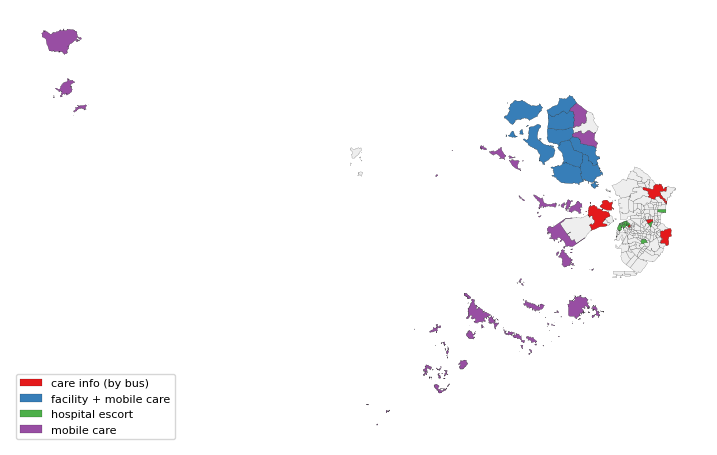

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# [셀 D5] 저장 + 대응 지도
import matplotlib.pyplot as plt
OUT = ["unit", "policy", "rank", "region", "hub"]
dm = dm.drop(columns=OUT, errors="ignore").merge(P[["adm_cd"] + OUT], on="adm_cd", how="left")
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
cols = ["rank", "adm_nm", "vuln", "pattern", "unit", "cluster_nm", "policy", "region", "eld_65", "eld_single"] + ZC
P[cols].round(2).sort_values(["policy", "rank"]).to_csv("policy_matrix.csv", index=False, encoding="utf-8-sig")
EN = {"의료시설 확충 검토 + 이동형 의료": "facility + mobile care", "이동형 의료": "mobile care",
      "병원 동행": "hospital escort", "의료 정보 제공": "care info (by bus)"}
m = g[["adm_cd", "geometry"]].merge(dm[["adm_cd", "policy"]], on="adm_cd"); m["pol"] = m["policy"].map(EN)
ax = m.plot(color="#eeeeee", edgecolor="k", linewidth=0.1, figsize=(9, 9))
m[m["pol"].notna()].plot("pol", ax=ax, categorical=True, legend=True, cmap="Set1", edgecolor="k", linewidth=0.1,
                          legend_kwds={"loc": "lower left", "fontsize": 8})
ax.axis("off"); plt.show()
files.download("dong_master.csv"); files.download("policy_matrix.csv")